# Machine Learning

In [1]:
# Importing the modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Loading the dataset

In [2]:
dataframe=pd.read_csv('dataset.csv')

## Displaying the first 10 rows of the dataset

In [3]:
dataframe.head(10)

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.000
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.000
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.000
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.000
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.000
5,6,2,audi fox,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250.000
6,7,1,audi 100ls,gas,std,four,sedan,fwd,front,105.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,17710.000
7,8,1,audi 5000,gas,std,four,wagon,fwd,front,105.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,18920.000
8,9,1,audi 4000,gas,turbo,four,sedan,fwd,front,105.8,...,131,mpfi,3.13,3.40,8.3,140,5500,17,20,23875.000
9,10,0,audi 5000s (diesel),gas,turbo,two,hatchback,4wd,front,99.5,...,131,mpfi,3.13,3.40,7.0,160,5500,16,22,17859.167


## Displaying information about the dataset

In [4]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

## Checking for duplicate rows

In [5]:
dataframe.duplicated().sum()

np.int64(0)

***No duplicate rows have been identified in the dataset.***

## Checking for missing values

In [6]:
dataframe.isna().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

***No missing values have been identified in the dataset.***

## Displaying statistical information about the dataset

In [7]:
dataframe.drop(columns=['car_ID','symboling']).describe()

,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## Checking for outliers

In [8]:
# Creating a copy of the dataframe
dataframe_copy=dataframe.copy()

In [9]:
# Extracting numeric columns
numeric_cols=dataframe_copy.drop(columns=['car_ID','symboling']).select_dtypes(include=['number']).columns
numeric_cols

Index(['wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight',
       'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower',
       'peakrpm', 'citympg', 'highwaympg', 'price'],
      dtype='str')

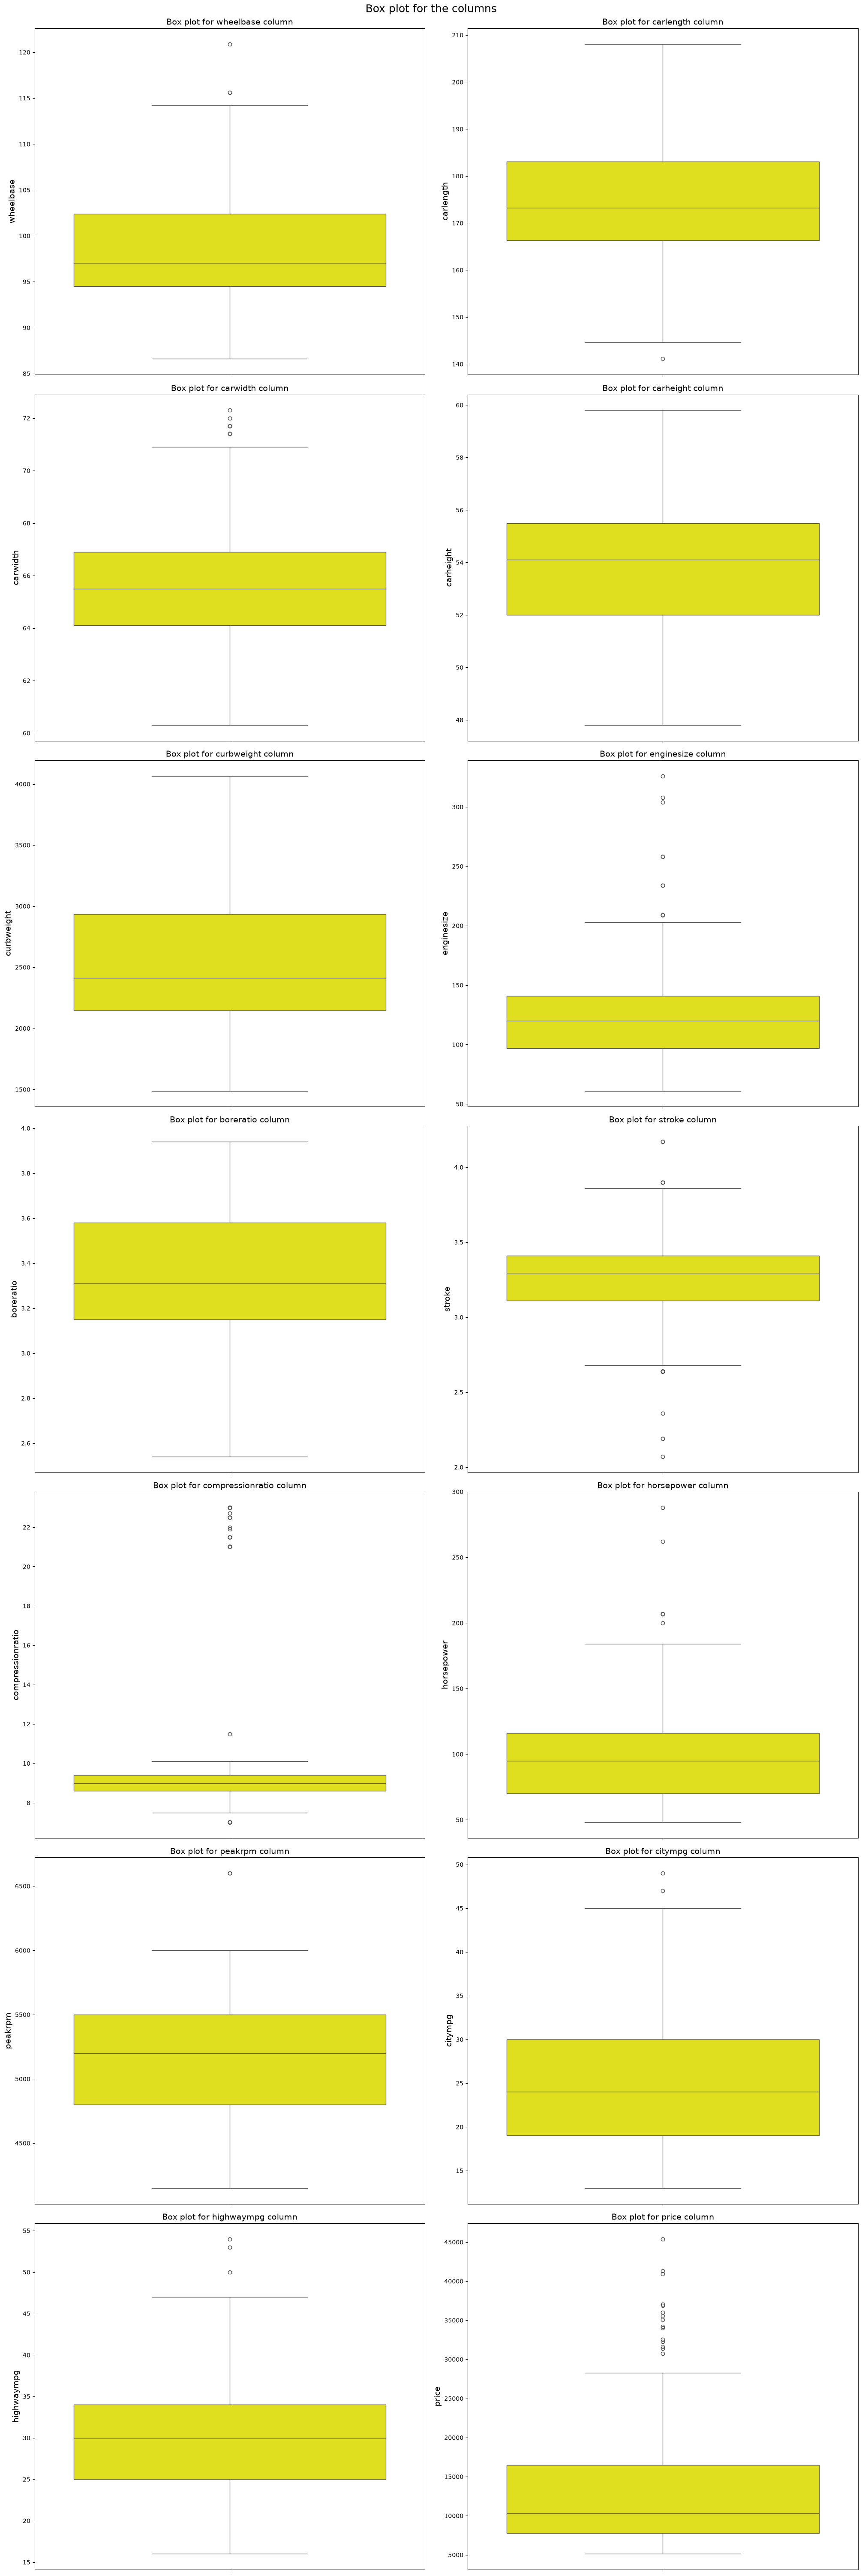

In [10]:
# plotting box plots 
fig, ax=plt.subplots(7,2, figsize=(20,60), constrained_layout=True)
count=0
for i in range(7):
    for j in range(2):
        sns.boxplot(
            data=dataframe_copy,
            y=numeric_cols[count],
            ax=ax[i][j],
            color='yellow'
        )
        ax[i][j].set_title(f"Box plot for {numeric_cols[count]} column", fontsize=14)
        ax[i][j].set_ylabel(numeric_cols[count], fontsize=14)
        count+=1
fig.suptitle("Box plot for the columns", fontsize=18)
plt.show()

***Except columns carheight, curbweight and boreratio, all other columns have outliers.***

In [11]:
# Removing the outliers
no_rows_removed=0
outlier_map={}
for i in numeric_cols:
    q1=dataframe_copy[i].quantile(0.25)
    q3=dataframe_copy[i].quantile(0.75)
    IQR=q3-q1
    lower_bound=q1-1.5*IQR
    upper_bound=q3+1.5*IQR
    outlier_mask=(dataframe_copy[i]<lower_bound) | (dataframe_copy[i]>upper_bound)
    outlier_count=outlier_mask.sum()
    if outlier_count>0:
        outlier_map[i]={"lower_bound":lower_bound, "upper_bound":upper_bound}
for i in outlier_map.keys():
    outlier_mask=(dataframe_copy[i]<outlier_map[i]['lower_bound']) | (dataframe_copy[i]>outlier_map[i]['upper_bound'])
    outlier_count=outlier_mask.sum()
    no_rows_removed+=outlier_count
    dataframe_copy=dataframe_copy[~outlier_mask]
print(f"Number of rows removed: {no_rows_removed}")

Number of rows removed: 66


## Checking for skewness

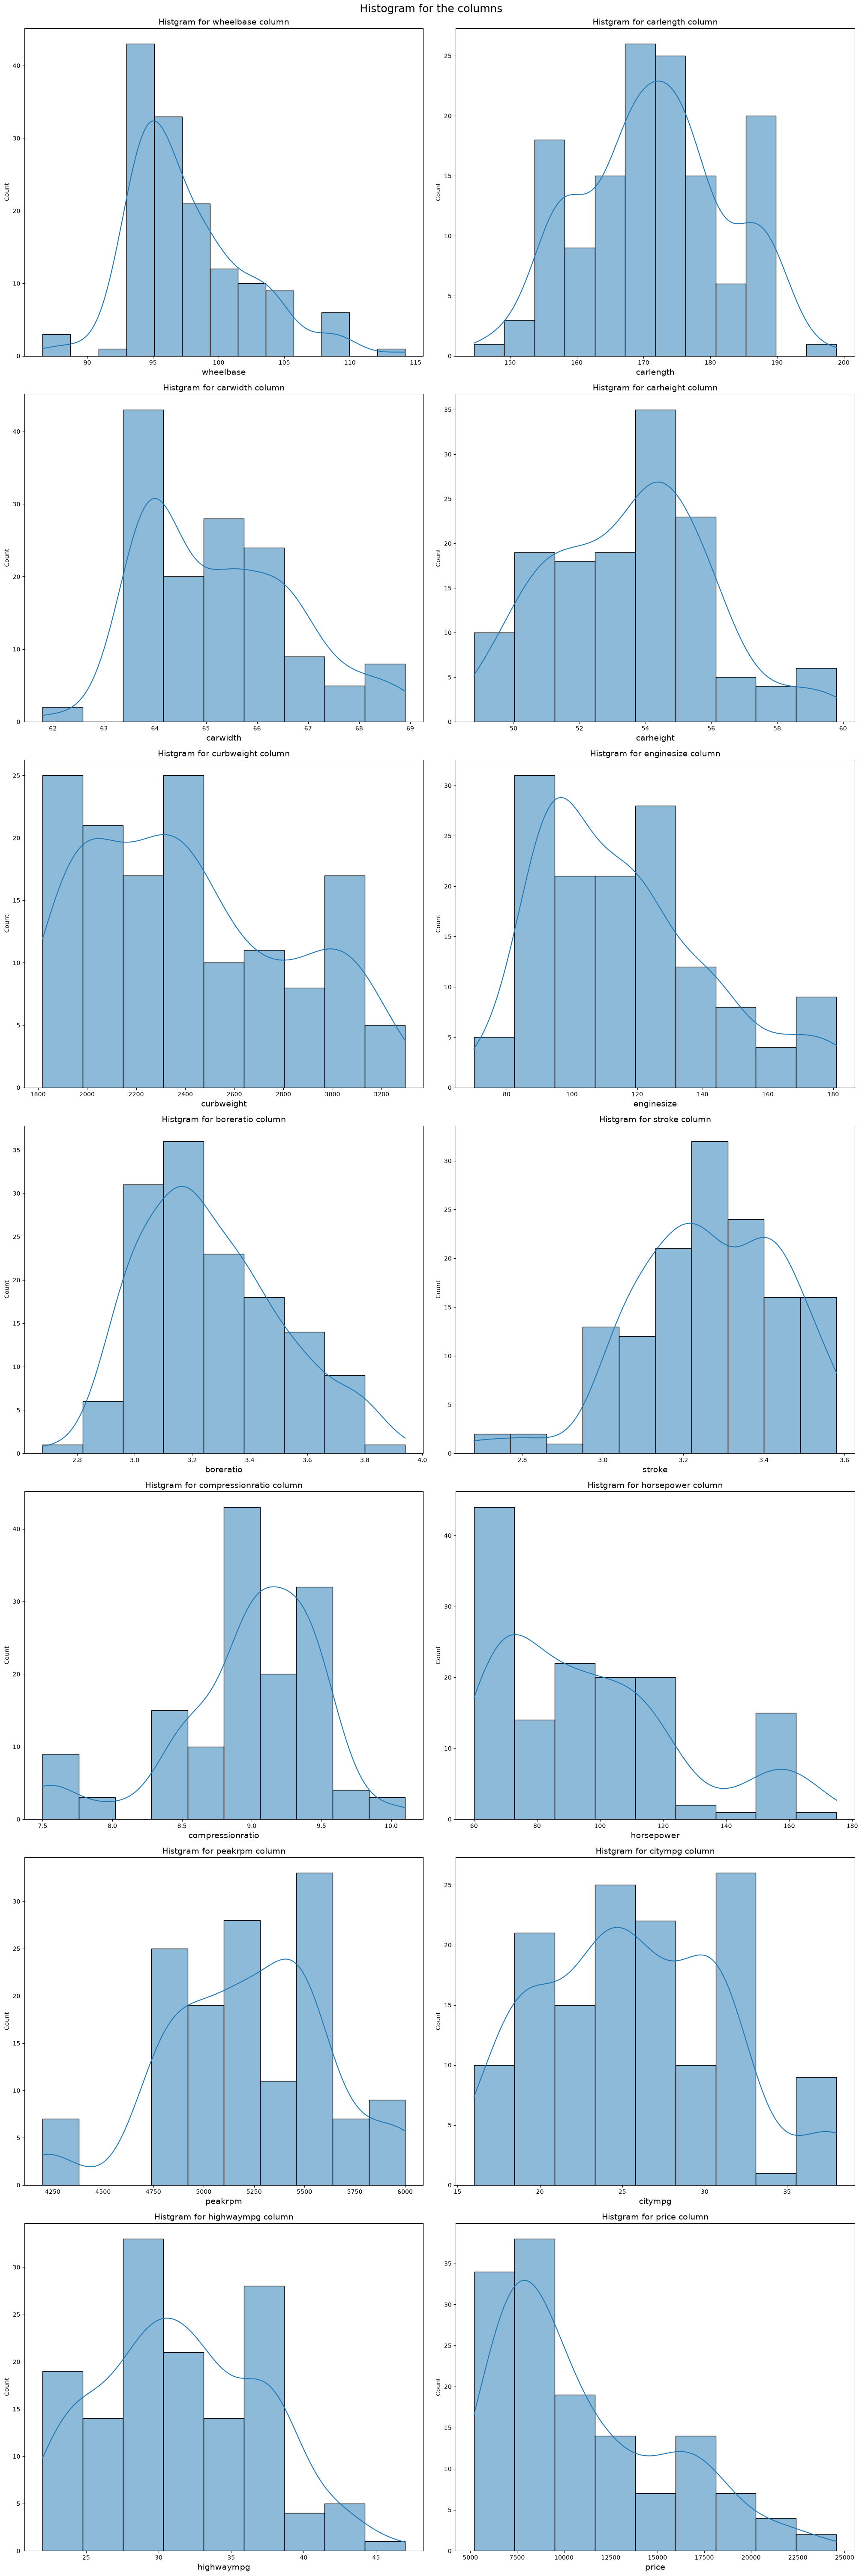

In [12]:
# plotting histograms
fig, ax=plt.subplots(7,2, figsize=(20,60), constrained_layout=True)
count=0
for i in range(7):
    for j in range(2):
        sns.histplot(
            data=dataframe_copy,
            x=numeric_cols[count],
            ax=ax[i][j],
            kde=True
        )
        ax[i][j].set_title(f"Histgram for {numeric_cols[count]} column", fontsize=14)
        ax[i][j].set_xlabel(numeric_cols[count], fontsize=14)
        count+=1
fig.suptitle("Histogram for the columns", fontsize=18)
plt.show()

In [13]:
# displaying skewness values of columns
for i in numeric_cols:
    skew_value=dataframe_copy[i].skew()
    print(f"Skewness value for {i} column: {skew_value}")

Skewness value for wheelbase column: 0.9253716873939191
Skewness value for carlength column: 0.01593170909262804
Skewness value for carwidth column: 0.5283631484034857
Skewness value for carheight column: 0.24115516123332284
Skewness value for curbweight column: 0.443463241880277
Skewness value for enginesize column: 0.8114419240084254
Skewness value for boreratio column: 0.5221657163219506
Skewness value for stroke column: -0.5118269737135646
Skewness value for compressionratio column: -1.1221107477440673
Skewness value for horsepower column: 0.8902532970266566
Skewness value for peakrpm column: -0.2850256009092441
Skewness value for citympg column: 0.31078567762548953
Skewness value for highwaympg column: 0.21399012222947056
Skewness value for price column: 0.9153055547288919


***Skewness have been identified in the following columns***
1. wheelbase
2. carwidth
3. enginesize
4. boreratio
5. stroke
6. compressionratio
7. horsepower
8. price

***Since price column is the target column, skewness of that column is not corrected.***

In [14]:
# selecting the columns
columns=['wheelbase','carwidth','enginesize', 'boreratio', 'stroke', 'compressionratio','horsepower']
moderately_positively_skewed=[]
highly_positively_skewed=[]
moderately_negatively_skewed=[]
highly_negatively_skewed=[]
for i in columns:
    skew_value=dataframe_copy[i].skew()
    if skew_value>0:
        if skew_value>1:
            highly_positively_skewed.append(i)
        elif skew_value>=0.5:
            moderately_positively_skewed.append(i)
    else:
        if skew_value<-1:
            highly_negatively_skewed.append(i)
        elif skew_value<=-0.5:
            moderately_negatively_skewed.append(i)
print(f"Highly positively skewed columns are: {highly_positively_skewed}")
print(f"Moderately positively skewed columns are: {moderately_positively_skewed}")
print(f"Highly negatively skewed columns are: {highly_negatively_skewed}")
print(f"Moderately negatively skewed columns: {moderately_negatively_skewed}")

Highly positively skewed columns are: []
Moderately positively skewed columns are: ['wheelbase', 'carwidth', 'enginesize', 'boreratio', 'horsepower']
Highly negatively skewed columns are: ['compressionratio']
Moderately negatively skewed columns: ['stroke']


## Encoding

**The categorical columns are:**
1. CarName
2. fueltype
3. aspiration
4. doornumber
5. carbody
6. drivewheel
7. enginelocation
8. enginetype
9. cylindernumber
10. fuelsystem

**CarName column is irrelevant so no encoding is applied to that column.**

**fueltype column**

In [15]:
# finding unique values in this column
dataframe_copy['fueltype'].value_counts()

fueltype
gas    139
Name: count, dtype: int64

**fueltype column has one unique value and is nominal column so using one-hot encoding.**

In [16]:
dataframe_copy=pd.get_dummies(data=dataframe_copy, columns=['fueltype'])

**aspiration column**

In [17]:
# finding unique values in this column
dataframe_copy['aspiration'].value_counts()

aspiration
std      126
turbo     13
Name: count, dtype: int64

**aspiration column has two unique values and is nominal column so using one-hot encoding.**

In [18]:
dataframe_copy=pd.get_dummies(data=dataframe_copy, columns=['aspiration'], drop_first=True)

**doornumber column**

In [19]:
# finding unique values in this column
dataframe_copy['doornumber'].value_counts()

doornumber
four    76
two     63
Name: count, dtype: int64

**doornumber column has two unique values and is nominal column. Since the door number represents a numerical value, using mapping for encoding.**

In [20]:
door_mapping={"four":4, "two":2}
dataframe_copy['doornumber']=dataframe_copy['doornumber'].map(door_mapping)

**carbody column**

In [21]:
# finding unique values in this column
dataframe_copy['carbody'].value_counts()

carbody
sedan          63
hatchback      53
wagon          15
convertible     4
hardtop         4
Name: count, dtype: int64

**carbody column has five unique values and is nominal column so using one-hot encoding.** 

In [22]:
dataframe_copy=pd.get_dummies(data=dataframe_copy, columns=['carbody'], drop_first=True)

**drivewheel column**

In [23]:
# finding unique values in this column
dataframe_copy['drivewheel'].value_counts()

drivewheel
fwd    92
rwd    44
4wd     3
Name: count, dtype: int64

**drivewheel column has three unique values and is nominal column so using one-hot encoding.**

In [24]:
dataframe_copy=pd.get_dummies(data=dataframe_copy, columns=['drivewheel'], drop_first=True)

**enginelocation column**

In [25]:
# finding unique values in this column
dataframe_copy['enginelocation'].value_counts()

enginelocation
front    139
Name: count, dtype: int64

**enginelocation column has one unique value and is nominal column so using one-hot encoding.**

In [26]:
dataframe_copy=pd.get_dummies(data=dataframe_copy, columns=['enginelocation'])

**enginetype column**

In [27]:
# finding unique values in this column
dataframe_copy['enginetype'].value_counts()

enginetype
ohc      117
dohc       8
ohcv       7
rotor      4
l          3
Name: count, dtype: int64

**enginetype column has five unique values and is nominal column so using one-hot encoding.**

In [28]:
dataframe_copy=pd.get_dummies(data=dataframe_copy, columns=['enginetype'], drop_first=True)

**cylindernumber column**

In [29]:
# finding unique values in this column
dataframe_copy['cylindernumber'].value_counts()

cylindernumber
four    118
six      14
two       4
five      3
Name: count, dtype: int64

**cylindernumber column has four unique values and is nominal column. Since cylindernumber represents a numerical value, using mapping for encoding.**

In [30]:
cylinder_mapping={
    "four":4,
    "six":6,
    "two":2,
    "five":5
}
dataframe_copy['cylindernumber']=dataframe_copy['cylindernumber'].map(cylinder_mapping)

**fuelsystem column**

In [31]:
# finding unique values in this column
dataframe_copy['fuelsystem'].value_counts()

fuelsystem
mpfi    63
2bbl    57
1bbl    10
spdi     5
4bbl     3
spfi     1
Name: count, dtype: int64

**fuelsystem column has five unique values and is nominal column so using one-hot encoding.**

In [32]:
dataframe_copy=pd.get_dummies(data=dataframe_copy, columns=['fuelsystem'], drop_first=True)

In [33]:
dataframe_copy.head(10)

,car_ID,symboling,CarName,doornumber,wheelbase,carlength,carwidth,carheight,curbweight,cylindernumber,...,enginelocation_front,enginetype_l,enginetype_ohc,enginetype_ohcv,enginetype_rotor,fuelsystem_2bbl,fuelsystem_4bbl,fuelsystem_mpfi,fuelsystem_spdi,fuelsystem_spfi
0,1,3,alfa-romero giulia,2,88.6,168.8,64.1,48.8,2548,4,...,True,False,False,False,False,False,False,True,False,False
1,2,3,alfa-romero stelvio,2,88.6,168.8,64.1,48.8,2548,4,...,True,False,False,False,False,False,False,True,False,False
2,3,1,alfa-romero Quadrifoglio,2,94.5,171.2,65.5,52.4,2823,6,...,True,False,False,True,False,False,False,True,False,False
3,4,2,audi 100 ls,4,99.8,176.6,66.2,54.3,2337,4,...,True,False,True,False,False,False,False,True,False,False
4,5,2,audi 100ls,4,99.4,176.6,66.4,54.3,2824,5,...,True,False,True,False,False,False,False,True,False,False
5,6,2,audi fox,2,99.8,177.3,66.3,53.1,2507,5,...,True,False,True,False,False,False,False,True,False,False
10,11,2,bmw 320i,2,101.2,176.8,64.8,54.3,2395,4,...,True,False,True,False,False,False,False,True,False,False
11,12,0,bmw 320i,4,101.2,176.8,64.8,54.3,2395,4,...,True,False,True,False,False,False,False,True,False,False
12,13,0,bmw x1,2,101.2,176.8,64.8,54.3,2710,6,...,True,False,True,False,False,False,False,True,False,False
13,14,0,bmw x3,4,101.2,176.8,64.8,54.3,2765,6,...,True,False,True,False,False,False,False,True,False,False


## Feature selection

**The columns car_ID, symboling and CarName are irrelevant columns so removing these columns.**

In [34]:
dataframe_copy=dataframe_copy.drop(columns=['car_ID','symboling','CarName'])

## Selecting the target

In [35]:
X=dataframe_copy.drop(columns=['price'])
y=dataframe_copy['price']

## Train - Test split

In [36]:
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42)

## Transformation

**Applying log transformation to highly positively skewed columns.**

In [37]:
X_train[highly_positively_skewed]=np.log1p(X_train[highly_positively_skewed])
X_test[highly_positively_skewed]=np.log1p(X_test[highly_positively_skewed])

**Applying squareroot transformation to moderately positively skewed columns.**

In [38]:
X_train[moderately_positively_skewed]=np.sqrt(X_train[moderately_positively_skewed])
X_test[moderately_positively_skewed]=np.sqrt(X_test[moderately_positively_skewed])

**Applying cube transformation to highly negatively skewed columns.**

In [39]:
X_train[highly_negatively_skewed]=X_train[highly_negatively_skewed]**3
X_test[highly_negatively_skewed]=X_test[highly_negatively_skewed]**3

**Applying square transformation to moderately negatively skewed columns.**

In [40]:
X_train[moderately_negatively_skewed]=np.square(X_train[moderately_negatively_skewed])
X_test[moderately_negatively_skewed]=np.square(X_test[moderately_negatively_skewed])

## Scaling

In [41]:
standard_scaler=StandardScaler()
X_train_scaled=standard_scaler.fit_transform(X_train)
X_test_scaled=standard_scaler.transform(X_test)

## Training the models

### Linear Regression

In [42]:
linear_regression=LinearRegression()
linear_regression.fit(X_train_scaled, y_train)
y_pred_linear_regression=linear_regression.predict(X_test_scaled)

In [43]:
mae_linear_regression=mean_absolute_error(y_true=y_test, y_pred=y_pred_linear_regression)
mse_linear_regression=mean_squared_error(y_true=y_test, y_pred=y_pred_linear_regression)
r2_linear_regression=r2_score(y_true=y_test, y_pred=y_pred_linear_regression)
print(f"Mean absolute error: {mae_linear_regression}")
print(f"Mean squared error: {mse_linear_regression}")
print(f"R2 score: {r2_linear_regression}")

Mean absolute error: 1516.1838206102068
Mean squared error: 3584526.5198046076
R2 score: 0.8081175697593379


### Decision Tree Regressor

In [44]:
decision_tree=DecisionTreeRegressor(random_state=42)
decision_tree.fit(X_train_scaled, y_train)
y_pred_decision_tree=decision_tree.predict(X_test_scaled)

In [45]:
mae_decision_tree=mean_absolute_error(y_true=y_test, y_pred=y_pred_decision_tree)
mse_decision_tree=mean_squared_error(y_true=y_test, y_pred=y_pred_decision_tree)
r2_decision_tree=r2_score(y_true=y_test, y_pred=y_pred_decision_tree)
print(f"Mean absolute error: {mae_decision_tree}")
print(f"Mean squared error: {mse_decision_tree}")
print(f"R2 score: {r2_decision_tree}")

Mean absolute error: 1560.857142857143
Mean squared error: 4893997.482142857
R2 score: 0.7380205934376958


### Random Forest Regressor

In [46]:
random_forest=RandomForestRegressor(random_state=42)
random_forest.fit(X_train_scaled, y_train)
y_pred_random_forest=random_forest.predict(X_test_scaled)

In [47]:
mae_random_forest=mean_absolute_error(y_true=y_test, y_pred=y_pred_random_forest)
mse_random_forest=mean_squared_error(y_true=y_test, y_pred=y_pred_random_forest)
r2_random_forest=r2_score(y_true=y_test, y_pred=y_pred_random_forest)
print(f"Mean absolute error: {mae_random_forest}")
print(f"Mean squared error: {mse_random_forest}")
print(f"R2 score: {r2_random_forest}")

Mean absolute error: 1193.545392857143
Mean squared error: 3228084.670104126
R2 score: 0.8271981730083644


### Gradient Boost Regressor

In [48]:
gradient_boost=GradientBoostingRegressor(random_state=42)
gradient_boost.fit(X_train_scaled, y_train)
y_pred_gradient_boost=gradient_boost.predict(X_test_scaled)

In [49]:
mae_gradient_boost=mean_absolute_error(y_true=y_test, y_pred=y_pred_gradient_boost)
mse_gradient_boost=mean_squared_error(y_true=y_test, y_pred=y_pred_gradient_boost)
r2_gradient_boost=r2_score(y_true=y_test, y_pred=y_pred_gradient_boost)
print(f"Mean absolute error: {mae_gradient_boost}")
print(f"Mean squared error: {mse_gradient_boost}")
print(f"R2 score: {r2_gradient_boost}")

Mean absolute error: 1238.9098687737485
Mean squared error: 3757624.157888167
R2 score: 0.7988515215711375


### Support Vector Regressor

In [50]:
svr=SVR()
svr.fit(X_train_scaled, y_train)
y_pred_svr=svr.predict(X_test_scaled)

In [51]:
mae_svr=mean_absolute_error(y_true=y_test, y_pred=y_pred_svr)
mse_svr=mean_squared_error(y_true=y_test, y_pred=y_pred_svr)
r2_svr=r2_score(y_true=y_test, y_pred=y_pred_svr)
print(f"Mean absolute error: {mae_svr}")
print(f"Mean squared error: {mse_svr}")
print(f"R2 score: {r2_svr}")

Mean absolute error: 3976.068949205512
Mean squared error: 26416462.17356194
R2 score: -0.4140933069452897


**The R2 score of SVC is negative because the target column has not been scaled. The feature columns have been scaled whereas the target column is in the range of very large numbers.**

## Comparison of models

In [52]:
comparison_df=pd.DataFrame(
    {
        "model":['Linear Regression', 'Decision Tree Regressor', 'Random Forest Regressor', 'Gradient Boost Regressor', 'Support Vector Regressor'],
        "mae":[mae_linear_regression, mae_decision_tree, mae_random_forest, mae_gradient_boost, mae_svr],
        "mse":[mse_linear_regression, mse_decision_tree, mse_random_forest, mse_gradient_boost, mse_svr],
        "r2_score":[r2_linear_regression, r2_decision_tree, r2_random_forest, r2_gradient_boost, r2_svr]
    }
)

In [53]:
comparison_df

,model,mae,mse,r2_score
0,Linear Regression,1516.183821,3.584527e+06,0.808118
1,Decision Tree Regressor,1560.857143,4.893997e+06,0.738021
2,Random Forest Regressor,1193.545393,3.228085e+06,0.827198
3,Gradient Boost Regressor,1238.909869,3.757624e+06,0.798852
4,Support Vector Regressor,3976.068949,2.641646e+07,-0.414093


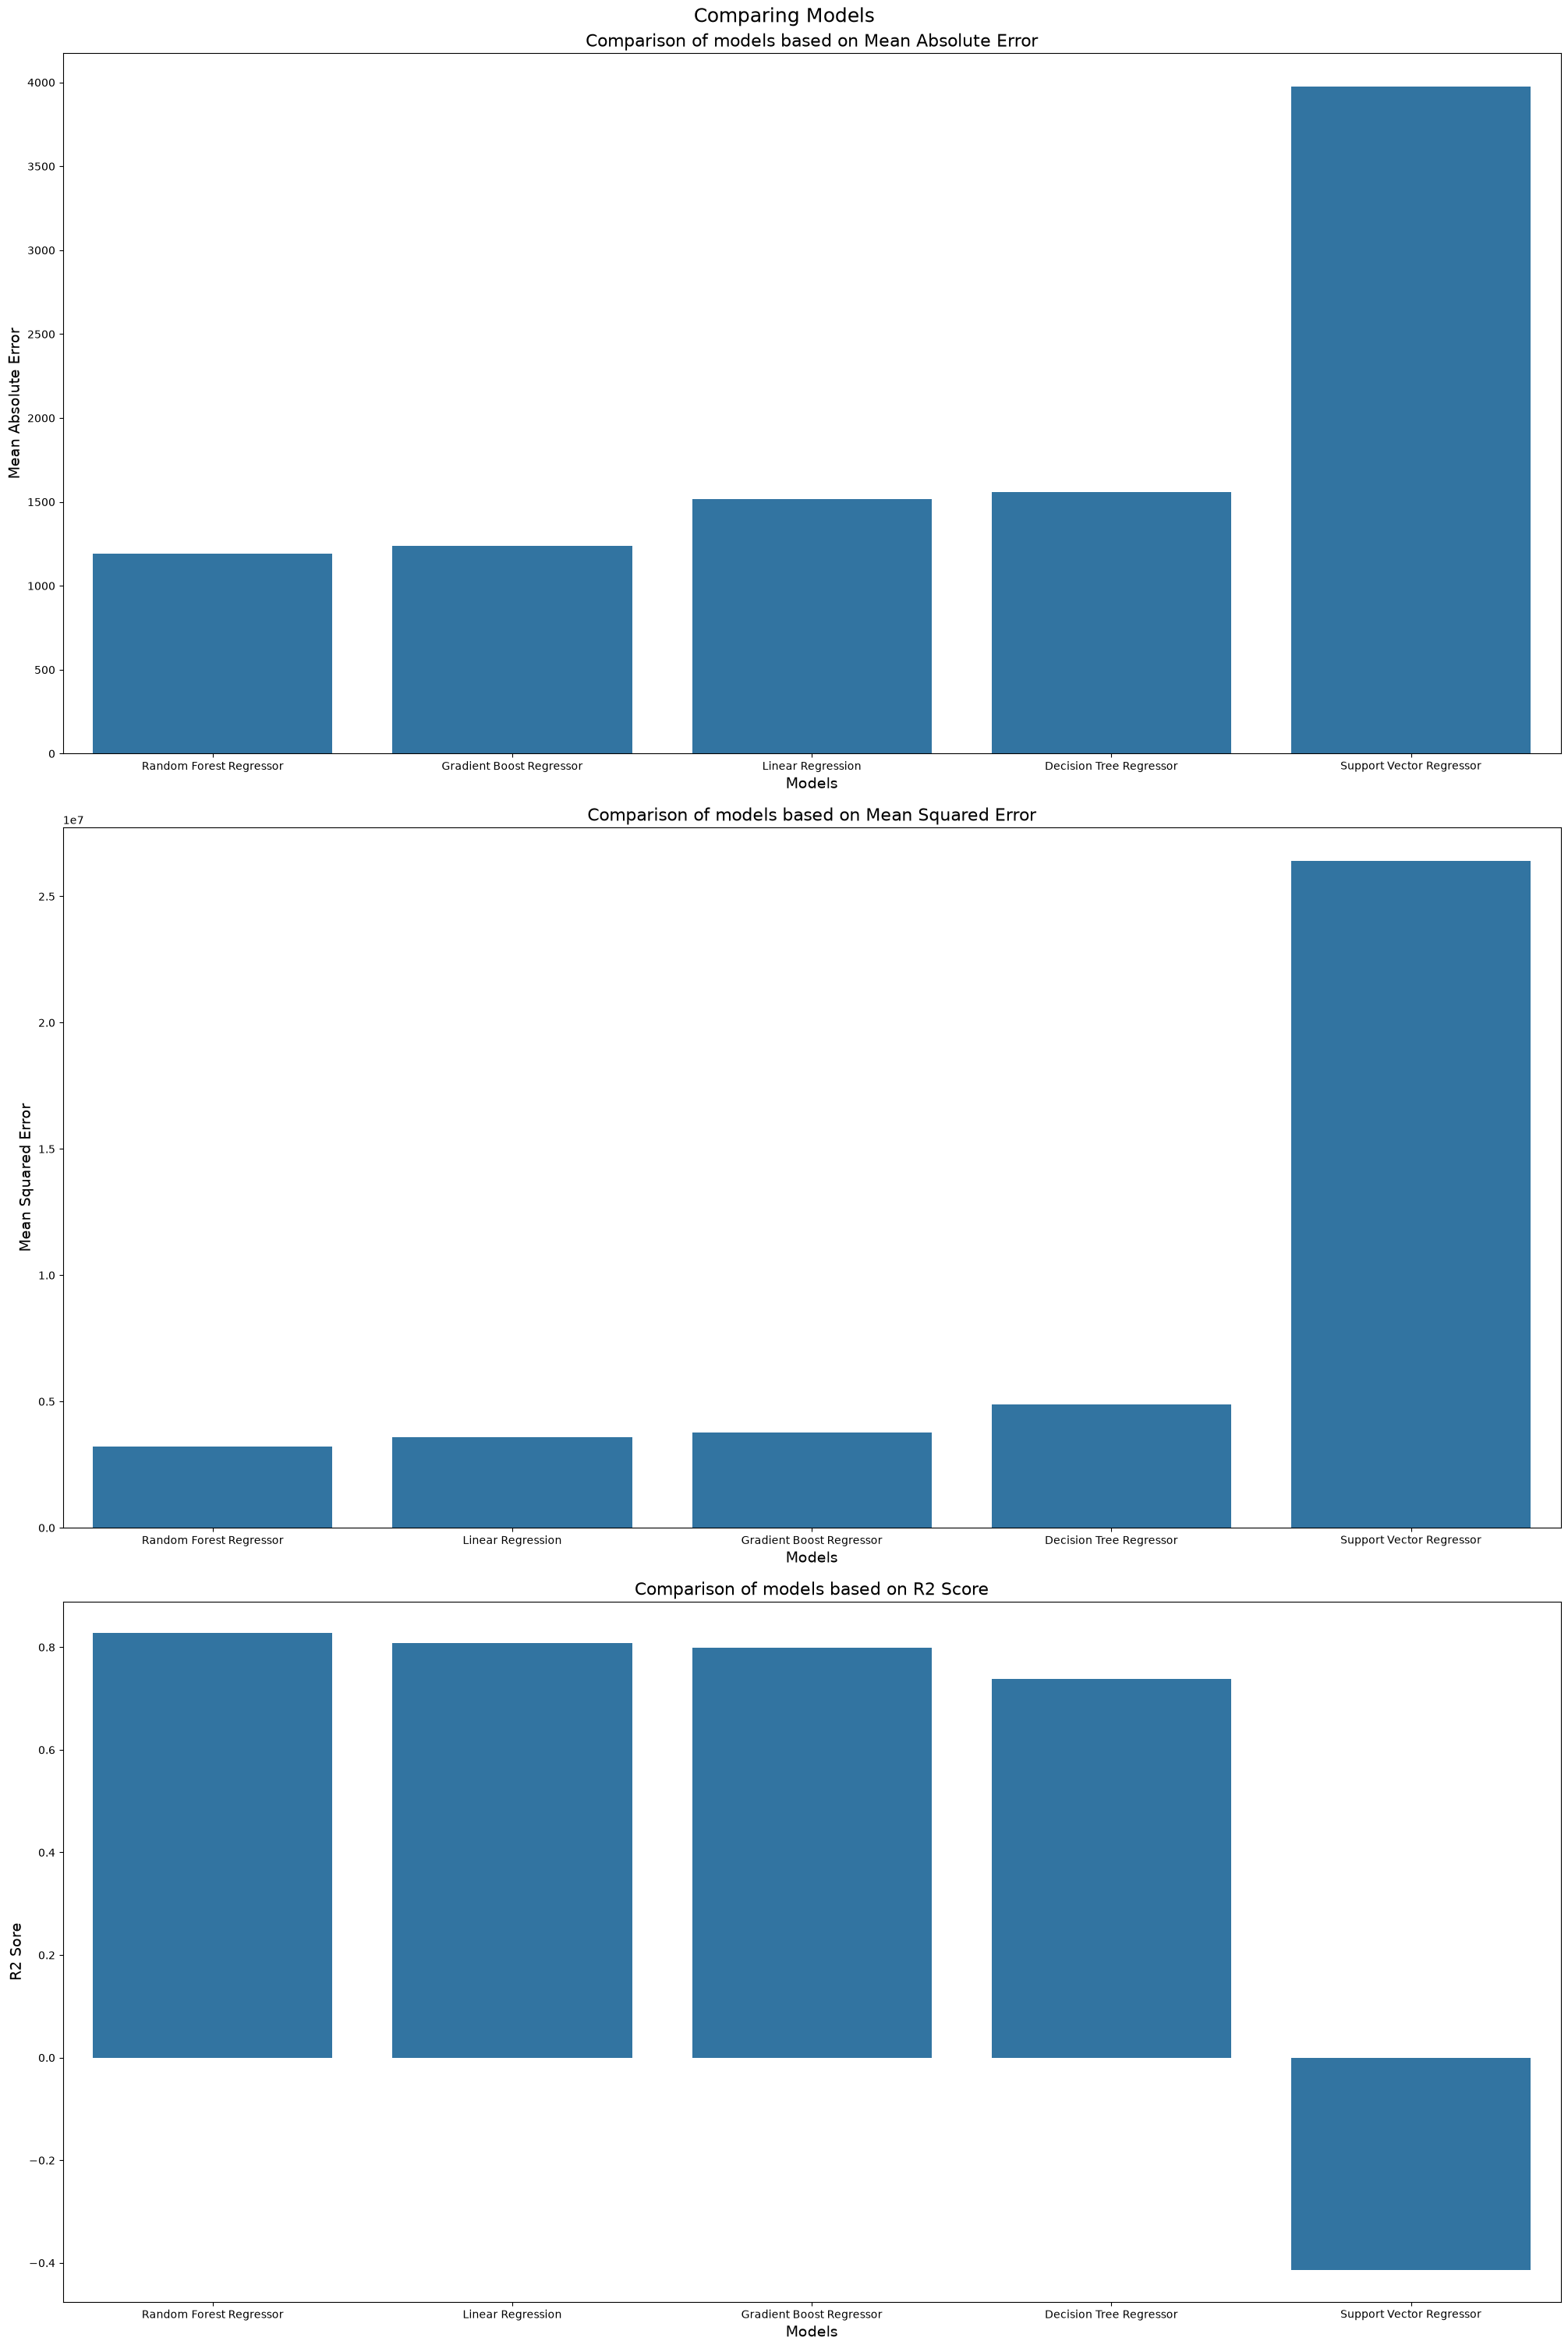

In [54]:
# plotting a graph for comparing the models
fig, ax=plt.subplots(3, figsize=(20,30), constrained_layout=True)
fig.suptitle("Comparing Models", fontsize=18)
ax[0].set_title("Comparison of models based on Mean Absolute Error", fontsize=16)
sns.barplot(
    data=comparison_df.sort_values(by='mae', ascending=True),
    x='model',
    y='mae',
    ax=ax[0]
)
ax[0].set_xlabel("Models", fontsize=14)
ax[0].set_ylabel("Mean Absolute Error", fontsize=14)
ax[1].set_title("Comparison of models based on Mean Squared Error", fontsize=16)
sns.barplot(
    data=comparison_df.sort_values(by='mse', ascending=True),
    x='model',
    y='mse',
    ax=ax[1]
)
ax[1].set_xlabel("Models", fontsize=14)
ax[1].set_ylabel("Mean Squared Error", fontsize=14)
ax[2].set_title("Comparison of models based on R2 Score", fontsize=16)
sns.barplot(
    data=comparison_df.sort_values(by="r2_score", ascending=False),
    x='model',
    y='r2_score',
    ax=ax[2]
)
ax[2].set_xlabel("Models", fontsize=14)
ax[2].set_ylabel("R2 Sore", fontsize=14)
plt.show()

**Random Forest Regressor have been identified as the best model based on Mean Absolute Error, Mean Squared Error and R2 Score. Random Forest became the best model because it is an ensemble model that splits the entire dataset into multiple bootstrap samples and trains a seperate decision tree on each sample. For regression it takes the average of the predictions.**

## Feature Importance Analysis

In [55]:
# function to extract original feature from encoded features
def extractor(feature):
    if '_' in feature:
        return feature.split('_')[0]
    return feature

In [56]:
feature_names=X_train.columns
importances=random_forest.feature_importances_
feature_importance_df=pd.DataFrame(
    {
        "encoded_feature":feature_names,
        "importance":importances
    }
)
feature_importance_df['original_feature']=feature_importance_df['encoded_feature'].apply(extractor)
feature_importance_df

,encoded_feature,importance,original_feature
0,doornumber,0.001154,doornumber
1,wheelbase,0.019380,wheelbase
2,carlength,0.020220,carlength
3,carwidth,0.022579,carwidth
4,carheight,0.008544,carheight
5,curbweight,0.055906,curbweight
6,cylindernumber,0.000854,cylindernumber
7,enginesize,0.016135,enginesize
8,boreratio,0.007173,boreratio
9,stroke,0.015014,stroke


In [57]:
feature_importance_df=feature_importance_df.drop(columns=['encoded_feature'])

In [58]:
importances=feature_importance_df.groupby(by=['original_feature'])['importance'].agg(['sum'])
importances

,sum
original_feature,
aspiration,0.005838
boreratio,0.007173
carbody,0.004576
carheight,0.008544
carlength,0.020220
carwidth,0.022579
citympg,0.086601
compressionratio,0.007037
curbweight,0.055906


In [59]:
importances=importances.sort_values(by='sum', ascending=False)
importances.head(10)

,sum
original_feature,
highwaympg,0.619380
citympg,0.086601
horsepower,0.073713
curbweight,0.055906
peakrpm,0.028385
carwidth,0.022579
carlength,0.020220
wheelbase,0.019380
enginesize,0.016135


**The 10 most important features affecting the price of the car:**
1. highwaympg
2. citympg
3. horsepower
4. curbweight
5. peakrpm
6. carwidth
7. carlength
8. wheelbase
9. enginesize
10. stroke

**Selecting only the important features**

In [60]:
dataframe_selected=dataframe_copy[[
'highwaympg',
'citympg',
'horsepower',
'curbweight',
'peakrpm',
'carwidth',
'carlength',
'wheelbase',
'enginesize',
'stroke',
'price'
]]

In [61]:
X=dataframe_selected.drop(columns=['price'])
y=dataframe_selected['price']
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42)
X_train[['wheelbase', 'carwidth', 'enginesize', 'horsepower']]=np.sqrt(X_train[['wheelbase', 'carwidth', 'enginesize', 'horsepower']])
X_test[['wheelbase', 'carwidth', 'enginesize', 'horsepower']]=np.sqrt(X_test[['wheelbase', 'carwidth', 'enginesize', 'horsepower']])
X_train['stroke']=np.square(X_train['stroke'])
X_test['stroke']=np.square(X_test['stroke'])
X_train_scaled=standard_scaler.fit_transform(X_train)
X_test_scaled=standard_scaler.transform(X_test)

## Hyper Parameter Tuning

In [62]:
gridsearch=GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid={
        "n_estimators":[100,300,500,1000],
        "max_depth":[None,10,20,30,40],
        "min_samples_split":[2,5,10],
        "min_samples_leaf":[1,2,4],
        "max_features":['sqrt','log2',0.5, 1.0],
        "bootstrap":[True,False]
    },
    n_jobs=-1,
    scoring='r2',
    cv=5
)
gridsearch.fit(X_train_scaled, y_train)
print("Best parameters are:")
print(gridsearch.best_params_)
print(f"Best cross validation R2 Score: {gridsearch.best_score_}")

Best parameters are:
{'bootstrap': True, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 1000}
Best cross validation R2 Score: 0.8154015430867899


In [63]:
rf=RandomForestRegressor(
    random_state=42,
    n_estimators=1000,
    bootstrap=True,
    max_depth=None,
    max_features='sqrt',
    min_samples_leaf=1,
    min_samples_split=2
)
rf.fit(X_train_scaled, y_train)
y_pred_rf=rf.predict(X_test_scaled)

In [64]:
mae_rf=mean_absolute_error(y_true=y_test, y_pred=y_pred_rf)
mse_rf=mean_squared_error(y_true=y_test, y_pred=y_pred_rf)
r2_rf=r2_score(y_true=y_test, y_pred=y_pred_rf)
print(f"Mean absolute error: {mae_rf}")
print(f"Mean squared error: {mse_rf}")
print(f"R2 score: {r2_rf}")

Mean absolute error: 1207.5584912414963
Mean squared error: 3355186.282948979
R2 score: 0.8203943270260761


**After hyper parameter tuning the R2 Score of the Random Forest Regressor model is remaining the same at 0.82.**

**Conclusion**
1. The dataset didnot have any missing or duplicate values.
2. The outliers were removed.
3. The skewness of the all the columns except the target column was corrected.
4. The data was scaled using StandardScaler.
5. Multiple models were trained on the dataset and the performance metrics were calculated. Based on the performance metrics Random Forest Regressor was identified as the best model.
6. The best features of the dataset were identified using Random Forest.
7. After using only these features the Random Forest Regressor model was hyper tuned using GridSearchCV.
8. The R2 Score after feature selection and hyper parameter tuning is remaining the same as before because Random Forest is already a well performing and optimized algorithm and also we can conclude that the selected top 10 features are the only features that matter.